<a href="https://colab.research.google.com/github/Adhilzcsworld/Practice-Questions/blob/main/Airqualitypattern_Investigation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AIR QUALITY PATTERN INVESTIGATION

### A Statistical Analysis of Pollutant Concentrations Using R

**Subject:** Data Analytics  
**Programme:** M.Tech Artificial Intelligence  
**Dataset:** UCI Air Quality Dataset  
**Tools and Technologies:** R, Tidyverse, ggplot2

## Project Overview

This project investigates patterns in air-quality measurements using statistical analysis and data visualization. The study focuses on carbon monoxide (CO) and nitrogen dioxide (NO₂), two pollutants measured in the UCI Air Quality dataset.

The analysis involves data inspection, identification of invalid sensor readings, data cleaning, descriptive statistics, Pearson correlation analysis, and hypothesis testing to compare CO concentrations during daytime and night-time.

The project aims to extract meaningful insights from the observed measurements and communicate the findings through statistical summaries, hypothesis tests, and graphical representations.

## 1. Introduction

Air quality is an important environmental factor that affects human health and overall quality of life. Monitoring pollutants and understanding their patterns can help identify relationships between different pollutants and variations in concentration over time.

Data analytics provides statistical techniques for examining environmental measurements, identifying trends, testing hypotheses, and communicating findings through visualizations.

This project uses the UCI Air Quality dataset to investigate pollutant concentration patterns. The analysis is conducted in R and focuses on CO and NO₂ measurements. Descriptive statistics are used to summarize the distributions, Pearson correlation is applied to examine their linear association, and Welch's two-sample t-test is used to compare mean CO concentrations between daytime and night-time.

### 1.1 Problem Statement

To investigate the distribution, linear relationship, and time-period variation of selected air pollutants using appropriate data preparation, statistical methods, and visualizations.

### 1.2 Objectives

1. Import the dataset and inspect its structure, variable types, and unusual values.
2. Identify invalid sensor readings and handle missing observations appropriately.
3. Calculate the mean, median, variance, standard deviation, and interquartile range of CO and NO₂.
4. Examine the linear association between CO and NO₂ using Pearson correlation.
5. Compare daytime and night-time mean CO concentrations using a suitable hypothesis test.
6. Present the findings using statistical outputs and graphical visualizations.

### 1.3 Tools and Libraries

The analysis is performed using R. The Tidyverse package is used for data manipulation, preprocessing, and visualization, including the `dplyr`, `tidyr`, and `ggplot2` packages. Base R functions are used for descriptive statistics, correlation testing, and hypothesis testing.

In [203]:
install.packages("tidyverse")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



## 2. Dataset Description and Import

The UCI Air Quality dataset contains hourly observations of air pollutants and environmental variables collected by an air-quality monitoring system. The dataset includes pollutant measurements, sensor responses, temperature, relative humidity, and absolute humidity.

The original dataset loaded in this notebook contains **9,471 rows and 17 columns**, including the date and time fields. The date and time information is used to construct a datetime variable for time-based analysis.

The dataset is imported into R for structural inspection and subsequent preprocessing. Initial inspection is performed using functions such as `head()`, `dim()`, `str()`, and `summary()`.

### Purpose of initial inspection

- Determine the number of observations and variables.
- Identify the data type of each variable.
- Inspect representative observations.
- Examine ranges, summary statistics, and unusual sensor values.
- Identify columns that contain no valid observations.

In [204]:
library(tidyverse)

In [205]:
data <- read.csv2(
  "AirQualityUCI.csv",
  header = TRUE,
  na.strings = ""
)

In [206]:
head(data)

,Date,Time,CO.GT.,PT08.S1.CO.,NMHC.GT.,C6H6.GT.,PT08.S2.NMHC.,NOx.GT.,PT08.S3.NOx.,NO2.GT.,PT08.S4.NO2.,PT08.S5.O3.,T,RH,AH,X,X.1
,<chr>,<chr>,<dbl>,<int>,<int>,<dbl>,<int>,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<lgl>,<lgl>
1,10/03/2004,18.00.00,2.6,1360,150,11.9,1046,166,1056,113,1692,1268,13.6,48.9,0.7578,NA,NA
2,10/03/2004,19.00.00,2.0,1292,112,9.4,955,103,1174,92,1559,972,13.3,47.7,0.7255,NA,NA
3,10/03/2004,20.00.00,2.2,1402,88,9.0,939,131,1140,114,1555,1074,11.9,54.0,0.7502,NA,NA
4,10/03/2004,21.00.00,2.2,1376,80,9.2,948,172,1092,122,1584,1203,11.0,60.0,0.7867,NA,NA
5,10/03/2004,22.00.00,1.6,1272,51,6.5,836,131,1205,116,1490,1110,11.2,59.6,0.7888,NA,NA
6,10/03/2004,23.00.00,1.2,1197,38,4.7,750,89,1337,96,1393,949,11.2,59.2,0.7848,NA,NA


In [207]:
dim(data)

[1] 9471   17

In [208]:
str(data)

'data.frame':	9471 obs. of  17 variables:
 $ Date         : chr  "10/03/2004" "10/03/2004" "10/03/2004" "10/03/2004" ...
 $ Time         : chr  "18.00.00" "19.00.00" "20.00.00" "21.00.00" ...
 $ CO.GT.       : num  2.6 2 2.2 2.2 1.6 1.2 1.2 1 0.9 0.6 ...
 $ PT08.S1.CO.  : int  1360 1292 1402 1376 1272 1197 1185 1136 1094 1010 ...
 $ NMHC.GT.     : int  150 112 88 80 51 38 31 31 24 19 ...
 $ C6H6.GT.     : num  11.9 9.4 9 9.2 6.5 4.7 3.6 3.3 2.3 1.7 ...
 $ PT08.S2.NMHC.: int  1046 955 939 948 836 750 690 672 609 561 ...
 $ NOx.GT.      : int  166 103 131 172 131 89 62 62 45 -200 ...
 $ PT08.S3.NOx. : int  1056 1174 1140 1092 1205 1337 1462 1453 1579 1705 ...
 $ NO2.GT.      : int  113 92 114 122 116 96 77 76 60 -200 ...
 $ PT08.S4.NO2. : int  1692 1559 1555 1584 1490 1393 1333 1333 1276 1235 ...
 $ PT08.S5.O3.  : int  1268 972 1074 1203 1110 949 733 730 620 501 ...
 $ T            : num  13.6 13.3 11.9 11 11.2 11.2 11.3 10.7 10.7 10.3 ...
 $ RH           : num  48.9 47.7 54 60 59.6 59.2

In [209]:
summary(data)

        Date             Time          CO.GT.         PT08.S1.CO.  
 Length   :9471   Length   :9471   Min.   :-200.00   Min.   :-200  
 N.unique : 391   N.unique :  24   1st Qu.:   0.60   1st Qu.: 921  
 N.blank  :   0   N.blank  :   0   Median :   1.50   Median :1053  
 Min.nchar:  10   Min.nchar:   8   Mean   : -34.21   Mean   :1049  
 Max.nchar:  10   Max.nchar:   8   3rd Qu.:   2.60   3rd Qu.:1221  
 NAs      : 114   NAs      : 114   Max.   :  11.90   Max.   :2040  
                                   NAs    :114       NAs    :114   
    NMHC.GT.         C6H6.GT.        PT08.S2.NMHC.       NOx.GT.      
 Min.   :-200.0   Min.   :-200.000   Min.   :-200.0   Min.   :-200.0  
 1st Qu.:-200.0   1st Qu.:   4.000   1st Qu.: 711.0   1st Qu.:  50.0  
 Median :-200.0   Median :   7.900   Median : 895.0   Median : 141.0  
 Mean   :-159.1   Mean   :   1.866   Mean   : 894.6   Mean   : 168.6  
 3rd Qu.:-200.0   3rd Qu.:  13.600   3rd Qu.:1105.0   3rd Qu.: 284.0  
 Max.   :1189.0   Max.   :  63

## 3. Initial Data Inspection

The initial inspection was performed to understand the structure and quality of the dataset before conducting statistical analysis.

The dataset contains date and time variables, pollutant measurements, sensor readings, and meteorological variables. The `str()` output identifies the data types, while `summary()` provides descriptive information such as minimum values, quartiles, medians, means, and maximum values for numerical variables.

The initial summary revealed the presence of **-200 values** in several numerical variables. These values are used in the UCI Air Quality dataset to represent missing or invalid sensor measurements. Therefore, they must be handled before calculating descriptive statistics or performing statistical tests.

Two additional columns, identified as `X` and `X.1`, contain no valid observations. These columns are not useful for the subsequent analysis and are removed during preprocessing.

## Identification of Invalid Sensor Readings(Identify unsual -200 Values)

In [210]:
sapply(data, function(x) sum(x == -200, na.rm = TRUE))

Date          Time        CO.GT.   PT08.S1.CO.      NMHC.GT. 
            0             0          1683           366          8443 
     C6H6.GT. PT08.S2.NMHC.       NOx.GT.  PT08.S3.NOx.       NO2.GT. 
          366           366          1639           366          1642 
 PT08.S4.NO2.   PT08.S5.O3.             T            RH            AH 
          366           366           366           366           366 
            X           X.1 
            0             0

In [211]:
colSums(is.na(data))

Date          Time        CO.GT.   PT08.S1.CO.      NMHC.GT. 
          114           114           114           114           114 
     C6H6.GT. PT08.S2.NMHC.       NOx.GT.  PT08.S3.NOx.       NO2.GT. 
          114           114           114           114           114 
 PT08.S4.NO2.   PT08.S5.O3.             T            RH            AH 
          114           114           114           114           114 
            X           X.1 
         9471          9471

In [212]:
colSums(!is.na(data))

Date          Time        CO.GT.   PT08.S1.CO.      NMHC.GT. 
         9357          9357          9357          9357          9357 
     C6H6.GT. PT08.S2.NMHC.       NOx.GT.  PT08.S3.NOx.       NO2.GT. 
         9357          9357          9357          9357          9357 
 PT08.S4.NO2.   PT08.S5.O3.             T            RH            AH 
         9357          9357          9357          9357          9357 
            X           X.1 
            0             0

## 4. Data Cleaning and Preprocessing

Data preprocessing is necessary to improve the reliability of the statistical analysis. Invalid sensor values, missing observations, and unnecessary columns are examined and handled before the analytical dataset is constructed.

### 4.1 Identification of Invalid Sensor Readings

The value **-200** is used in the UCI Air Quality dataset to indicate missing or invalid sensor measurements. Treating this value as a valid numerical observation would distort the calculated means, variances, standard deviations, and other statistical measures.

The number of -200 readings is counted for each numerical variable using R. This step identifies the extent of invalid measurements before cleaning.

### 4.2 Handling Invalid Values

All numerical values equal to -200 are replaced with `NA`, R's representation of a missing value. This ensures that invalid sensor readings are not treated as genuine pollutant concentrations.

### 4.3 Removal of Empty Columns

Columns containing only missing values are removed because they do not contribute useful information to the analysis. The cleaned dataset is then inspected to verify its dimensions and variable types.

### 4.4 Date-Time Preparation

The date and time fields are combined into a single datetime variable using `as.POSIXct()`. This transformation allows observations to be classified into daytime and night-time periods.

### 4.5 Missing-Value Strategy

Missing observations are handled according to the requirements of each analysis. For the CO–NO₂ analysis, observations missing either selected pollutant are excluded using `drop_na()`. For the time-period comparison, observations with missing CO measurements are excluded.

This analysis-specific approach retains usable observations for each task without requiring every variable in a row to be complete.

**Preprocessing rule:** Invalid numerical readings equal to -200 are converted to `NA`, completely empty columns are removed, and observations missing the variables required for a particular analysis are excluded from that analysis.

In [213]:
sapply(data, function(x) sum(x == -200, na.rm = TRUE))

Date          Time        CO.GT.   PT08.S1.CO.      NMHC.GT. 
            0             0          1683           366          8443 
     C6H6.GT. PT08.S2.NMHC.       NOx.GT.  PT08.S3.NOx.       NO2.GT. 
          366           366          1639           366          1642 
 PT08.S4.NO2.   PT08.S5.O3.             T            RH            AH 
          366           366           366           366           366 
            X           X.1 
            0             0

In [214]:
data_clean <- data %>%
  mutate(
    across(
      where(is.numeric),
      ~na_if(.x, -200)
    )
  )

In [215]:
sapply(data_clean, function(x) sum(x == -200, na.rm = TRUE))

Date          Time        CO.GT.   PT08.S1.CO.      NMHC.GT. 
            0             0             0             0             0 
     C6H6.GT. PT08.S2.NMHC.       NOx.GT.  PT08.S3.NOx.       NO2.GT. 
            0             0             0             0             0 
 PT08.S4.NO2.   PT08.S5.O3.             T            RH            AH 
            0             0             0             0             0 
            X           X.1 
            0             0

In [216]:
colSums(is.na(data_clean))

Date          Time        CO.GT.   PT08.S1.CO.      NMHC.GT. 
          114           114          1797           480          8557 
     C6H6.GT. PT08.S2.NMHC.       NOx.GT.  PT08.S3.NOx.       NO2.GT. 
          480           480          1753           480          1756 
 PT08.S4.NO2.   PT08.S5.O3.             T            RH            AH 
          480           480           480           480           480 
            X           X.1 
         9471          9471

In [217]:
data_clean <- data_clean %>%
  select(where(~ !all(is.na(.))))

In [218]:
dim(data_clean)

[1] 9471   15

In [219]:
str(data_clean)

'data.frame':	9471 obs. of  15 variables:
 $ Date         : chr  "10/03/2004" "10/03/2004" "10/03/2004" "10/03/2004" ...
 $ Time         : chr  "18.00.00" "19.00.00" "20.00.00" "21.00.00" ...
 $ CO.GT.       : num  2.6 2 2.2 2.2 1.6 1.2 1.2 1 0.9 0.6 ...
 $ PT08.S1.CO.  : int  1360 1292 1402 1376 1272 1197 1185 1136 1094 1010 ...
 $ NMHC.GT.     : int  150 112 88 80 51 38 31 31 24 19 ...
 $ C6H6.GT.     : num  11.9 9.4 9 9.2 6.5 4.7 3.6 3.3 2.3 1.7 ...
 $ PT08.S2.NMHC.: int  1046 955 939 948 836 750 690 672 609 561 ...
 $ NOx.GT.      : int  166 103 131 172 131 89 62 62 45 NA ...
 $ PT08.S3.NOx. : int  1056 1174 1140 1092 1205 1337 1462 1453 1579 1705 ...
 $ NO2.GT.      : int  113 92 114 122 116 96 77 76 60 NA ...
 $ PT08.S4.NO2. : int  1692 1559 1555 1584 1490 1393 1333 1333 1276 1235 ...
 $ PT08.S5.O3.  : int  1268 972 1074 1203 1110 949 733 730 620 501 ...
 $ T            : num  13.6 13.3 11.9 11 11.2 11.2 11.3 10.7 10.7 10.3 ...
 $ RH           : num  48.9 47.7 54 60 59.6 59.2 56.

In [220]:
data_clean <- data_clean %>%
  mutate(
    datetime = as.POSIXct(
      paste(Date, Time),
      format = "%d/%m/%Y %H.%M.%S"
    )
  )

In [221]:
head(data_clean[, c("Date", "Time", "datetime")])

,Date,Time,datetime
,<chr>,<chr>,<dttm>
1,10/03/2004,18.00.00,2004-03-10 18:00:00
2,10/03/2004,19.00.00,2004-03-10 19:00:00
3,10/03/2004,20.00.00,2004-03-10 20:00:00
4,10/03/2004,21.00.00,2004-03-10 21:00:00
5,10/03/2004,22.00.00,2004-03-10 22:00:00
6,10/03/2004,23.00.00,2004-03-10 23:00:00


In [222]:
missing_summary <- data_clean %>%
  summarise(
    across(
      everything(),
      ~sum(is.na(.))
    )
  )

missing_summary

Date,Time,CO.GT.,PT08.S1.CO.,NMHC.GT.,C6H6.GT.,PT08.S2.NMHC.,NOx.GT.,PT08.S3.NOx.,NO2.GT.,PT08.S4.NO2.,PT08.S5.O3.,T,RH,AH,datetime
<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
114,114,1797,480,8557,480,480,1753,480,1756,480,480,480,480,480,114


##Descriptive Statistics of Two Pollutants

In [223]:
names(data_clean)

[1] "Date"          "Time"          "CO.GT."        "PT08.S1.CO."  
 [5] "NMHC.GT."      "C6H6.GT."      "PT08.S2.NMHC." "NOx.GT."      
 [9] "PT08.S3.NOx."  "NO2.GT."       "PT08.S4.NO2."  "PT08.S5.O3."  
[13] "T"             "RH"            "AH"            "datetime"

## 5. Selection of Pollutants for Analysis

Two pollutant variables are selected for detailed statistical investigation:

- **CO(GT):** Reference measurement of carbon monoxide concentration.
- **NO₂(GT):** Reference measurement of nitrogen dioxide concentration.

These variables are selected to examine their individual distributions and investigate whether their observed concentrations exhibit a linear association.

A separate analytical dataset is created by selecting the datetime, CO, and NO₂ variables. Observations with missing values in either pollutant are excluded to ensure that both variables are available for each paired observation.

The resulting analytical dataset contains **7,258 complete observations and three columns**. This dataset is used for the descriptive statistics, pollutant distribution plot, Pearson correlation test, and scatterplot.

Using a consistent set of paired observations ensures that the correlation coefficient is calculated from observations for which both pollutant measurements are available.

In [224]:
pollutant_data <- data_clean %>%
  select(datetime, CO.GT., NO2.GT.) %>%
  drop_na(CO.GT., NO2.GT.)

In [225]:
head(pollutant_data)

,datetime,CO.GT.,NO2.GT.
,<dttm>,<dbl>,<int>
1,2004-03-10 18:00:00,2.6,113
2,2004-03-10 19:00:00,2.0,92
3,2004-03-10 20:00:00,2.2,114
4,2004-03-10 21:00:00,2.2,122
5,2004-03-10 22:00:00,1.6,116
6,2004-03-10 23:00:00,1.2,96


In [226]:
dim(pollutant_data)

[1] 7258    3

In [227]:
names(data_clean)

[1] "Date"          "Time"          "CO.GT."        "PT08.S1.CO."  
 [5] "NMHC.GT."      "C6H6.GT."      "PT08.S2.NMHC." "NOx.GT."      
 [9] "PT08.S3.NOx."  "NO2.GT."       "PT08.S4.NO2."  "PT08.S5.O3."  
[13] "T"             "RH"            "AH"            "datetime"

## 6. Descriptive Statistical Analysis

Descriptive statistics summarize the central tendency and variability of the selected pollutant concentrations. The mean, median, variance, standard deviation, and interquartile range (IQR) are calculated for CO and NO₂.

### 6.1 Statistical Measures

- **Mean:** The arithmetic average of the observed measurements.
- **Median:** The middle value of the ordered observations.
- **Variance:** A measure of the dispersion of observations around the mean, expressed in squared units.
- **Standard deviation:** A measure of dispersion expressed in the original measurement units.
- **Interquartile range (IQR):** The difference between the third quartile and the first quartile, representing the spread of the middle 50% of observations.

### 6.2 Distribution Visualization

A boxplot is constructed to examine the distributions and identify potential extreme observations. The plot displays the median, interquartile range, whiskers, and observations identified as outliers under the boxplot rule.

Because CO and NO₂ are measured on different numerical scales, the combined boxplot is primarily useful for examining distribution shape and potential outliers within each pollutant. The numerical magnitude of the two pollutants should not be directly compared without considering their respective units and scales.

In [228]:
descriptive_stats <- data.frame(
  Statistic = c(
    "Mean",
    "Median",
    "Variance",
    "Standard Deviation",
    "IQR"
  ),

  CO = c(
    mean(pollutant_data$CO.GT.),
    median(pollutant_data$CO.GT.),
    var(pollutant_data$CO.GT.),
    sd(pollutant_data$CO.GT.),
    IQR(pollutant_data$CO.GT.)
  ),

  NO2 = c(
    mean(pollutant_data$NO2.GT.),
    median(pollutant_data$NO2.GT.),
    var(pollutant_data$NO2.GT.),
    sd(pollutant_data$NO2.GT.),
    IQR(pollutant_data$NO2.GT.)
  )
)

descriptive_stats

Statistic,CO,NO2
<chr>,<dbl>,<dbl>
Mean,2.205635,114.81193
Median,1.900000,110.00000
Variance,2.126636,2327.49239
Standard Deviation,1.458299,48.24409
IQR,1.800000,64.00000


In [229]:
summary(pollutant_data[, c("CO.GT.", "NO2.GT.")])

     CO.GT.          NO2.GT.     
 Min.   : 0.100   Min.   :  2.0  
 1st Qu.: 1.100   1st Qu.: 80.0  
 Median : 1.900   Median :110.0  
 Mean   : 2.206   Mean   :114.8  
 3rd Qu.: 2.900   3rd Qu.:144.0  
 Max.   :11.900   Max.   :340.0  

In [230]:
pollutant_long <- pollutant_data %>%
  select(CO.GT., NO2.GT.) %>%
  pivot_longer(
    cols = everything(),
    names_to = "Pollutant",
    values_to = "Concentration"
  )

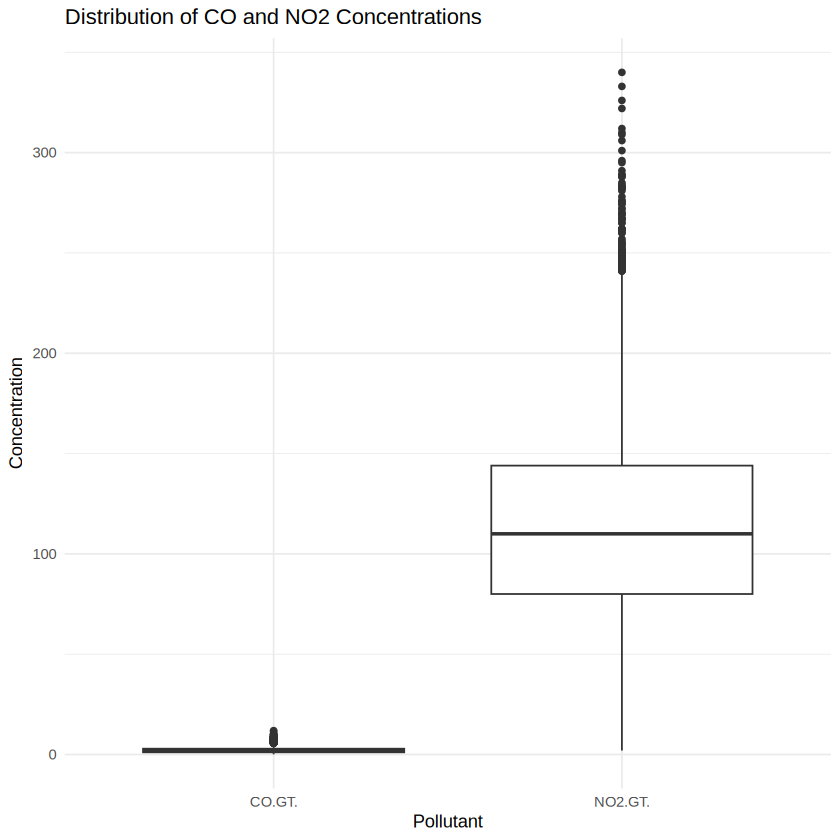

In [231]:
ggplot(pollutant_long, aes(x = Pollutant, y = Concentration)) +
  geom_boxplot() +
  labs(
    title = "Distribution of CO and NO2 Concentrations",
    x = "Pollutant",
    y = "Concentration"
  ) +
  theme_minimal()

In [232]:
descriptive_stats

Statistic,CO,NO2
<chr>,<dbl>,<dbl>
Mean,2.205635,114.81193
Median,1.900000,110.00000
Variance,2.126636,2327.49239
Standard Deviation,1.458299,48.24409
IQR,1.800000,64.00000


In [233]:
summary(pollutant_data[, c("CO.GT.", "NO2.GT.")])

     CO.GT.          NO2.GT.     
 Min.   : 0.100   Min.   :  2.0  
 1st Qu.: 1.100   1st Qu.: 80.0  
 Median : 1.900   Median :110.0  
 Mean   : 2.206   Mean   :114.8  
 3rd Qu.: 2.900   3rd Qu.:144.0  
 Max.   :11.900   Max.   :340.0  

### 6.3 Interpretation of Descriptive Statistics

The descriptive statistics indicate that the mean CO concentration is approximately **2.2056**, while the median is **1.9000**. For NO₂, the mean is approximately **114.8119**, and the median is **110.0000**.

For both pollutants, the mean is greater than the median, which is consistent with some degree of right-skewness in the observed distributions. The standard deviations are approximately **1.4583 for CO** and **48.2441 for NO₂**, indicating variation in both sets of measurements.

The IQR values are **1.8000 for CO** and **64.0000 for NO₂**. The boxplot also displays high-value observations beyond the upper whiskers. These observations are potential outliers under the boxplot rule and should not automatically be considered erroneous measurements without further evidence.

Overall, the descriptive analysis demonstrates that the observed pollutant concentrations vary considerably and that their distributions contain relatively high observations.

## Pearson Correlation Analysis (Finding linear association using pearson co-relation)

## 7. Pearson Correlation Analysis

Pearson's product-moment correlation coefficient is used to examine the strength and direction of the linear association between CO and NO₂ concentrations.

The correlation coefficient, denoted by \(r\), ranges from -1 to +1. A positive value indicates that the two variables tend to increase together, whereas a negative value indicates an inverse linear relationship. Values closer to zero indicate a weaker linear association.

### 7.1 Hypotheses

**Null hypothesis**
**H₀:** There is no linear association between CO and NO₂ concentrations ($\rho = 0$).

**Alternative hypothesis (H₁):**

**H₁:** There is a linear association between CO and NO₂ concentrations ($\rho \neq 0$).


**Significance level:** $\alpha = 0.05$
### 7.2 Statistical Test

The `cor.test()` function in R is used to conduct a two-sided Pearson correlation test. The analysis reports the sample correlation coefficient, test statistic, degrees of freedom, p-value, and 95% confidence interval.

### 7.3 Decision Rule

If the p-value is less than 0.05, the null hypothesis is rejected. Otherwise, the null hypothesis is not rejected.

The results are interpreted in the context of the selected pollutant measurements. A statistically significant correlation indicates evidence of a linear association, but it does not establish that one pollutant causes changes in the other.### Hypothesis

In [234]:
cor_test <- cor.test(
  pollutant_data$CO.GT.,
  pollutant_data$NO2.GT.,
  method = "pearson"
)

cor_test


	Pearson's product-moment correlation

data:  pollutant_data$CO.GT. and pollutant_data$NO2.GT.
t = 79.727, df = 7256, p-value < 2.2e-16
alternative hypothesis: true correlation is not equal to 0
95 percent confidence interval:
 0.6708833 0.6954163
sample estimates:
      cor 
0.6833427 


---

Pearson's correlation test revealed a statistically significant positive linear association between CO and NO₂ concentrations ($r = 0.6833$), $t(7256) = 79.727$, $p < 2.2 \times 10^{-16}$.

Since the p-value is below the significance level of 0.05, the null hypothesis of zero population correlation is rejected. The positive correlation indicates that higher CO concentrations tend to occur alongside higher NO₂ concentrations in the analyzed observations. However, this association does not establish a causal relationship.

`geom_smooth()` using formula = 'y ~ x'


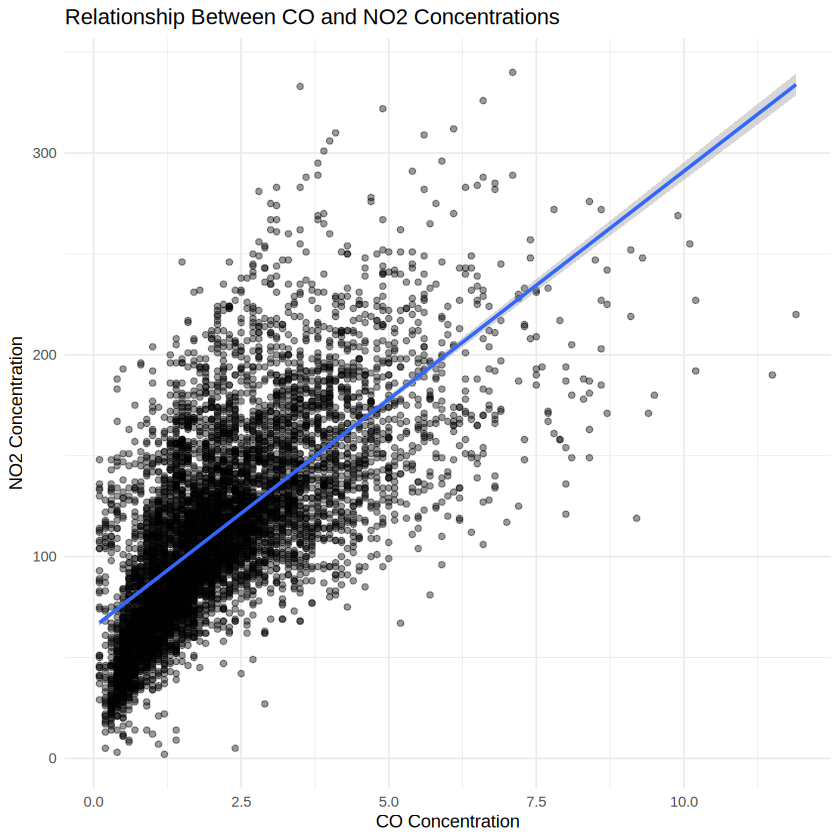

In [235]:
ggplot(pollutant_data, aes(x = CO.GT., y = NO2.GT.)) +
  geom_point(alpha = 0.4) +
  geom_smooth(method = "lm", se = TRUE) +
  labs(
    title = "Relationship Between CO and NO2 Concentrations",
    x = "CO Concentration",
    y = "NO2 Concentration"
  ) +
  theme_minimal()

### 7.4 Results and Interpretation

The Pearson correlation analysis produced a correlation coefficient of **r = 0.6833**, with a test statistic of **t = 79.727**, **7,256 degrees of freedom**, and **p < 2.2 × 10⁻¹⁶**. The 95% confidence interval for the population correlation is approximately **0.6709 to 0.6954**.

Since the p-value is below the significance level of 0.05, the null hypothesis is rejected. The results provide strong statistical evidence of a positive linear association between CO and NO₂ concentrations in the analyzed observations.

The scatterplot supports this finding by showing an overall upward trend, also reflected in the fitted regression line. Higher CO measurements tend to occur alongside higher NO₂ measurements in this dataset.

However, the association should not be interpreted as evidence of causation. Other environmental factors and common emission sources may contribute to the observed relationship.

##DAYTIME VS NIGHT TIME ANALYSIS

## 8. Daytime versus Night-Time Analysis

This analysis investigates whether the mean CO concentration differs between daytime and night-time observations. The datetime variable is used to extract the hour of each observation and assign it to one of two periods.

### 8.1 Definition of Time Periods

For this study, the periods are defined as follows:

- **Daytime:** 06:00 to 17:59.
- **Night-time:** 18:00 to 05:59.

This classification is an analytical choice used to compare observations across two consistent time intervals.

### 8.2 Descriptive Comparison

The mean, median, standard deviation, and number of valid CO observations are calculated separately for each period. These measures provide an initial understanding of the differences in central tendency and variability before hypothesis testing.

### 8.3 Hypotheses

**Null hypothesis (H₀):** The population mean CO concentration is equal during daytime and night-time, \(\mu_{\text{day}} = \mu_{\text{night}}\).

**Alternative hypothesis (H₁):** The population mean CO concentration differs between daytime and night-time, \(\mu_{\text{day}} \neq \mu_{\text{night}}\).

**Significance level:** \(\alpha = 0.05\).

### 8.4 Choice of Statistical Test

Welch's two-sample t-test is used to compare the means of the two independent groups. This version of the t-test does not require the two groups to have equal population variances.

The test evaluates whether the observed difference between the sample means provides sufficient statistical evidence of a difference between the population means.

In [236]:
data_clean <- data_clean %>%
  mutate(
    hour = as.integer(format(datetime, "%H"))
  )

In [237]:
data_clean <- data_clean %>%
  mutate(
    period = ifelse(
      hour >= 6 & hour < 18,
      "Daytime",
      "Night-time"
    )
  )

In [238]:
day_night_data <- data_clean %>%
  select(datetime, CO.GT., period) %>%
  drop_na(CO.GT.)

In [239]:
head(day_night_data)

,datetime,CO.GT.,period
,<dttm>,<dbl>,<chr>
1,2004-03-10 18:00:00,2.6,Night-time
2,2004-03-10 19:00:00,2.0,Night-time
3,2004-03-10 20:00:00,2.2,Night-time
4,2004-03-10 21:00:00,2.2,Night-time
5,2004-03-10 22:00:00,1.6,Night-time
6,2004-03-10 23:00:00,1.2,Night-time


In [240]:
day_night_summary <- day_night_data %>%
  group_by(period) %>%
  summarise(
    n = n(),
    mean_CO = mean(CO.GT.),
    median_CO = median(CO.GT.),
    sd_CO = sd(CO.GT.)
  )

day_night_summary

period,n,mean_CO,median_CO,sd_CO
<chr>,<int>,<dbl>,<dbl>,<dbl>
Daytime,3903,2.251550,2.0,1.323502
Night-time,3771,2.050491,1.6,1.569979


### Hypothesis

**H₀:** The mean CO concentration is equal during daytime and night-time ($\mu_{day} = \mu_{night}$).

**H₁:** The mean CO concentration differs between daytime and night-time ($\mu_{day} \neq \mu_{night}$).

**Significance level:** $\alpha = 0.05$

##T- Test

In [241]:
day_night_test <- t.test(
  CO.GT. ~ period,
  data = day_night_data,
  var.equal = FALSE
)

day_night_test


	Welch Two Sample t-test

data:  CO.GT. by period
t = 6.0555, df = 7368.3, p-value = 1.469e-09
alternative hypothesis: true difference in means between group Daytime and group Night-time is not equal to 0
95 percent confidence interval:
 0.1359725 0.2661465
sample estimates:
   mean in group Daytime mean in group Night-time 
                2.251550                 2.050491 


In [242]:
data_clean <- data_clean %>%
  mutate(
    hour = as.integer(format(datetime, "%H"))
  )

In [243]:
data_clean <- data_clean %>%
  mutate(
    period = ifelse(
      hour >= 6 & hour < 18,
      "Daytime",
      "Night-time"
    )
  )

table(data_clean$period)


   Daytime Night-time 
      4677       4680 

In [244]:
day_night_data <- data_clean %>%
  select(datetime, CO.GT., period) %>%
  drop_na(CO.GT.)

day_night_summary <- day_night_data %>%
  group_by(period) %>%
  summarise(
    n = n(),
    mean_CO = mean(CO.GT.),
    median_CO = median(CO.GT.),
    sd_CO = sd(CO.GT.)
  )

day_night_summary

period,n,mean_CO,median_CO,sd_CO
<chr>,<int>,<dbl>,<dbl>,<dbl>
Daytime,3903,2.251550,2.0,1.323502
Night-time,3771,2.050491,1.6,1.569979


In [245]:
day_night_test <- t.test(
  CO.GT. ~ period,
  data = day_night_data,
  var.equal = FALSE
)

day_night_test


	Welch Two Sample t-test

data:  CO.GT. by period
t = 6.0555, df = 7368.3, p-value = 1.469e-09
alternative hypothesis: true difference in means between group Daytime and group Night-time is not equal to 0
95 percent confidence interval:
 0.1359725 0.2661465
sample estimates:
   mean in group Daytime mean in group Night-time 
                2.251550                 2.050491 


There is statistically significant evidence of a positive linear association between CO and NO₂ concentrations. The correlation coefficient of 0.6833 indicates a moderately strong positive linear relationship: higher CO concentrations tend to occur alongside higher NO₂ concentrations in the observed data. However, correlation does not imply causation.

## Daytime vs Night-time Analysis

The observations were divided into **daytime (06:00–17:59)** and **night-time (18:00–05:59)** periods.

For CO concentration, **3,903 valid daytime observations** and **3,771 valid night-time observations** were available. The mean CO concentration was **2.252 during daytime** and **2.050 during night-time**.

A **Welch two-sample t-test** was performed because the two groups may have unequal variances. The test produced $t = 6.0555$, $df = 7368.3$, and $p = 1.469 \times 10^{-9}$.

Since the p-value is less than **0.05**, the null hypothesis of equal mean CO concentrations was rejected. Thus, the data provide statistically significant evidence of a difference in mean CO concentration between daytime and night-time, with the observed daytime mean being approximately **0.20 units higher**.

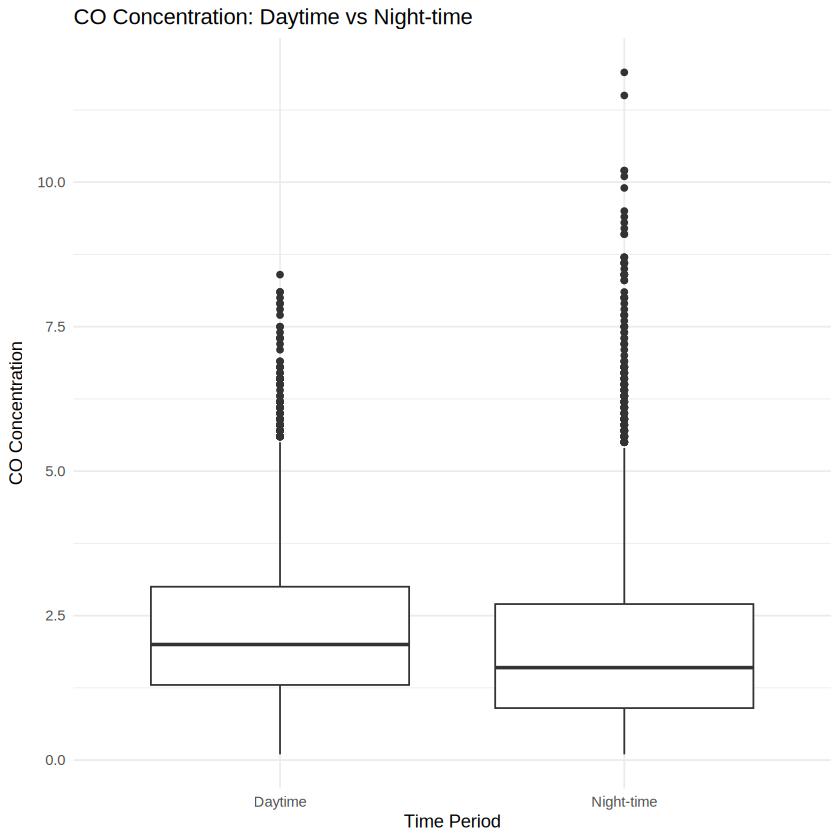

In [246]:
ggplot(day_night_data, aes(x = period, y = CO.GT.)) +
  geom_boxplot() +
  labs(
    title = "CO Concentration: Daytime vs Night-time",
    x = "Time Period",
    y = "CO Concentration"
  ) +
  theme_minimal()

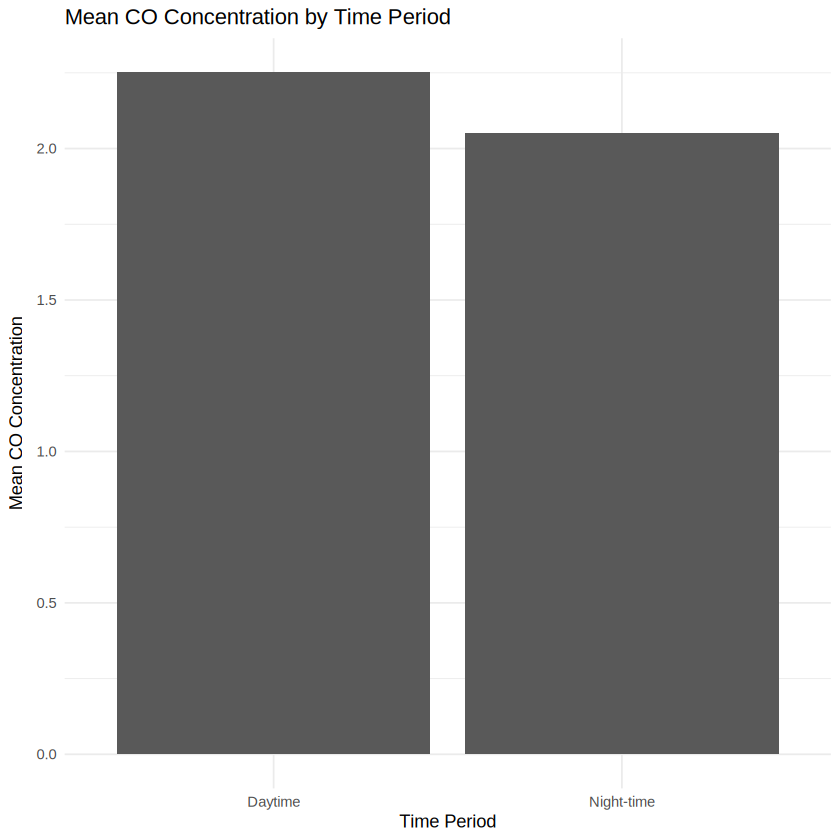

In [247]:
ggplot(day_night_summary, aes(x = period, y = mean_CO)) +
  geom_col() +
  labs(
    title = "Mean CO Concentration by Time Period",
    x = "Time Period",
    y = "Mean CO Concentration"
  ) +
  theme_minimal()

### 8.5 Results and Interpretation

The descriptive comparison shows a mean CO concentration of **2.2516 during daytime** and **2.0505 during night-time**. The observed difference between the means is approximately **0.2011 units**, with the daytime mean being higher.

Welch's two-sample t-test produced a test statistic of **t = 6.0555**, approximately **7,368.3 degrees of freedom**, and a p-value of **1.469 × 10⁻⁹**. The 95% confidence interval for the daytime-minus-night-time mean difference is approximately **0.1360 to 0.2661**.

Since the p-value is below 0.05, the null hypothesis is rejected. The findings provide statistically significant evidence of a difference in mean CO concentration between the two periods.

The boxplot provides a visual comparison of the distributions, while the mean comparison plot summarizes the difference in sample means. The observed difference is statistically significant, although its practical or environmental importance requires consideration of measurement units and contextual information.

These findings describe the observations in the dataset and should not be interpreted as proof that the time of day alone causes changes in CO concentration.

## 9. Overall Results and Discussion

The analysis examined the distribution of two pollutants, their linear association, and the variation in CO concentration across two time periods.

The descriptive statistics showed that both CO and NO₂ concentrations vary across observations. Their means were higher than their medians, consistent with right-skewness, and the boxplots identified high-value observations that warrant consideration when interpreting the distributions.

The Pearson correlation analysis identified a positive linear association between CO and NO₂, with \(r = 0.6833\) and \(p < 2.2 \times 10^{-16}\). This indicates that higher values of one pollutant tend to be associated with higher values of the other in the analyzed observations.

The daytime/night-time comparison identified a statistically significant difference in mean CO concentration. The observed daytime mean was approximately 0.2011 units higher than the night-time mean, and Welch's t-test produced \(p = 1.469 \times 10^{-9}\).

The results demonstrate the usefulness of descriptive statistics, correlation analysis, hypothesis testing, and visualization in identifying patterns in environmental data. Statistical significance should be interpreted alongside effect size, data quality, measurement context, and the limitations of the analysis.

## 10. Limitations of the Study

The findings should be interpreted in light of the following limitations:

1. **Missing observations:** Invalid sensor readings and missing values reduce the number of observations available for the analyses.
2. **Selected pollutants:** The detailed investigation focuses on CO and NO₂ rather than all variables in the dataset.
3. **Time-period definition:** The daytime and night-time intervals were selected for this study and may not represent every possible definition of these periods.
4. **Association versus causation:** Correlation and mean-comparison tests identify statistical patterns but do not establish causal relationships.
5. **Practical significance:** A statistically significant result does not automatically imply a large or environmentally important effect.
6. **Potential dependence between observations:** The measurements are hourly observations, so consecutive readings may be temporally related. The standard tests used here do not explicitly model time-series dependence.

These limitations provide context for interpreting the results and suggest possible directions for more advanced analysis.



## 11. Conclusion

This project investigated air-quality patterns in the UCI Air Quality dataset using R-based statistical analysis and visualization. The workflow included data inspection, preprocessing, descriptive statistics, Pearson correlation analysis, and a comparison of CO concentrations between daytime and night-time.

During preprocessing, invalid sensor readings represented by -200 were converted to missing values, and completely empty columns were removed. For the selected pollutant analysis, 7,258 complete paired observations were available.

Descriptive statistics showed variation in both CO and NO₂ concentrations, with the mean exceeding the median for both pollutants. Pearson correlation analysis identified a statistically significant positive linear association between CO and NO₂, with a correlation coefficient of 0.6833 and a p-value below 2.2 × 10⁻¹⁶.

The comparison of daytime and night-time CO concentrations also produced a statistically significant result. The daytime mean was approximately 2.2516, compared with 2.0505 during night-time. Welch's two-sample t-test yielded a p-value of 1.469 × 10⁻⁹, providing evidence of a difference in mean CO concentration between the two periods.

Overall, the project demonstrates how data preprocessing, descriptive measures, hypothesis testing, and graphical analysis can be combined to investigate environmental datasets. The findings reveal meaningful statistical patterns in the observed measurements while highlighting the importance of careful data cleaning and cautious interpretation.